# BFS and DFS on the Knight's Problem

This notebook follows the learning sequence below:

1. Use **Breadth-First Search (BFS)** to find a shortest knight path between two squares.
2. Attempt a similar BFS problem independently.
3. Understand a **closed Knight's Tour** and view its animation.
4. Use **Depth-First Search (DFS) with backtracking** as an exercise to find a closed tour.

Coordinates are written as `(row, column)`, with both values ranging from `0` to `7`.

## 1. Representing the chessboard as a graph

The knight problem can be represented as a graph:

- Each chessboard square is a **vertex**.
- A legal knight move between two squares is an **edge**.
- From a square $(r,c)$, the knight can attempt the coordinate changes

$$
(\pm 2,\pm 1) \quad \text{and} \quad (\pm 1,\pm 2).
$$

Only moves that remain inside the $8\times8$ board are legal.

## 2. How the knight's movement is programmed

Before applying BFS or DFS, the program must answer one basic question correctly:

> From the current square, which squares can the knight legally reach in one move?

### 2.1 Coordinate representation

Every square is represented by a Python tuple:

```python
(row, column)
```

For example:

```python
(0, 0)   # top-left square
(3, 5)   # row 3, column 5
(7, 7)   # bottom-right square
```

Since the board has eight rows and eight columns, a square is inside the board exactly when

```python
0 <= row < 8
0 <= column < 8
```

The program stores the board size as

```python
N = 8
```

so the boundary conditions are written as

```python
0 <= row < N
0 <= column < N
```

This is preferable to repeatedly writing the number `8`, because changing `N` changes the board size throughout the program.

### 2.2 Translating the knight's L-shaped move into coordinate changes

A knight moves:

- two squares in one direction and one square perpendicular to it; or
- one square in one direction and two squares perpendicular to it.

If `(row, column)` is the current square, a move is represented by

```python
(row_change, column_change)
```

The eight possible coordinate changes are stored as

```python
KNIGHT_MOVES = [
    (2, 1),
    (1, 2),
    (-1, 2),
    (-2, 1),
    (-2, -1),
    (-1, -2),
    (1, -2),
    (2, -1)
]
```

Their meanings are:

- `(2, 1)`: move two rows downward and one column right;
- `(1, 2)`: move one row downward and two columns right;
- `(-1, 2)`: move one row upward and two columns right;
- `(-2, 1)`: move two rows upward and one column right;
- `(-2, -1)`: move two rows upward and one column left;
- `(-1, -2)`: move one row upward and two columns left;
- `(1, -2)`: move one row downward and two columns left;
- `(2, -1)`: move two rows downward and one column left.

The signs indicate direction:

- positive row change: downward;
- negative row change: upward;
- positive column change: right;
- negative column change: left.

Together, these eight pairs describe every possible orientation of the knight's L-shaped move.

### 2.3 Computing one candidate destination

Suppose the knight is at

```python
square = (3, 3)
```

and the program is examining the relative move

```python
(2, 1)
```

It separates the current coordinates:

```python
row, col = square
```

so that

```python
row = 3
col = 3
```

It then adds the relative changes:

```python
next_row = row + row_change
next_col = col + col_change
```

Therefore,

```python
next_row = 3 + 2 = 5
next_col = 3 + 1 = 4
```

and the candidate destination is

```python
(5, 4)
```

### 2.4 Rejecting moves outside the board

Not every one of the eight coordinate changes produces a square inside the board.

For example, from `(0, 0)`, applying `(-2, -1)` gives

```python
next_row = 0 - 2 = -2
next_col = 0 - 1 = -1
```

The square `(-2, -1)` does not exist on the chessboard. Therefore, the program checks

```python
if 0 <= next_row < N and 0 <= next_col < N:
```

This condition contains four logical requirements:

```python
0 <= next_row       # not above the board
next_row < N        # not below the board
0 <= next_col       # not left of the board
next_col < N        # not right of the board
```

The word `and` means that all four requirements must be true. Only then is the destination appended to the list of legal neighbours.

### 2.5 Complete function for legal moves

```python
def legal_neighbours(square):
    row, col = square
    neighbours = []

    for row_change, col_change in KNIGHT_MOVES:
        next_row = row + row_change
        next_col = col + col_change

        if 0 <= next_row < N and 0 <= next_col < N:
            neighbours.append((next_row, next_col))

    return neighbours
```

The function operates in these logical steps:

1. Receive the current square.
2. Separate it into `row` and `col`.
3. Create an empty list called `neighbours`.
4. Examine each of the eight possible knight changes.
5. Add the changes to the current coordinates.
6. Test whether the resulting coordinates remain inside the board.
7. Append only valid destinations.
8. Return the complete list of legal one-move destinations.

### 2.6 Example from a corner

For

```python
legal_neighbours((0, 0))
```

six of the eight candidate moves leave the board. Only these remain valid:

```python
[(2, 1), (1, 2)]
```

Thus, a knight in a corner has only two legal moves.

### 2.7 Example from an interior square

For

```python
legal_neighbours((3, 3))
```

all eight destinations remain inside the board:

```python
[
    (5, 4), (4, 5), (2, 5), (1, 4),
    (1, 2), (2, 1), (4, 1), (5, 2)
]
```

### 2.8 Building the knight graph

BFS and DFS repeatedly ask for the neighbours of squares. Instead of recomputing them every time, the program computes them once:

```python
NEIGHBOURS = {
    (row, col): legal_neighbours((row, col))
    for row in range(N)
    for col in range(N)
}
```

This dictionary contains one entry for every square.

For example:

```python
NEIGHBOURS[(0, 0)]
```

returns

```python
[(2, 1), (1, 2)]
```

Here:

- the dictionary key `(0, 0)` is a graph vertex;
- the associated list contains all vertices joined to it by a legal knight move.

Therefore, `NEIGHBOURS` is an adjacency-list representation of the knight graph.

### 2.9 Why BFS and DFS can use the same movement code

The rules of movement do not change between BFS and DFS. Both algorithms use

```python
NEIGHBOURS[current]
```

to obtain all squares reachable from `current` in one legal knight move.

The difference lies only in how those neighbours are explored:

- BFS inserts unvisited neighbours into a queue and explores level by level.
- DFS selects a neighbour, extends the current path deeply, and backtracks when necessary.

Thus, the movement function defines the graph, while BFS and DFS define two different ways of searching that graph.

# Part A: BFS example first

## 3. Problem

Find a path requiring the **minimum number of knight moves** from

$$
(0,0) \quad \text{to} \quad (7,7).
$$

BFS is appropriate because every legal knight move has the same cost: one move.

### How BFS explores

- Level 0 contains the starting square.
- Level 1 contains squares first reached in one move.
- Level 2 contains squares first reached in two moves.
- The process continues level by level.

BFS uses a **queue**, which follows first-in, first-out order. A square is marked visited when it enters the queue. A `parent` dictionary records how each square was first reached, allowing the shortest path to be reconstructed.

### BFS pseudocode

```text
BFS(start, destination):
    create an empty queue
    insert start into the queue
    mark start as visited
    parent[start] = None
    distance[start] = 0

    while queue is not empty:
        current = remove the front square

        if current is destination:
            stop

        for each legal knight-neighbour next_square:
            if next_square is unvisited:
                mark next_square as visited
                parent[next_square] = current
                distance[next_square] = distance[current] + 1
                insert next_square at the rear of the queue

    reconstruct the path using parent references
```

Because BFS processes all squares at distance $d$ before processing any square at distance $d+1$, the first route it finds to the destination is a shortest route.

In [2]:
from collections import deque

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

N = 8

KNIGHT_MOVES = [
    (2, 1), (1, 2), (-1, 2), (-2, 1),
    (-2, -1), (-1, -2), (1, -2), (2, -1)
]


def legal_neighbours(square):
    """Return all squares reachable by one legal knight move."""
    row, col = square
    neighbours = []

    for row_change, col_change in KNIGHT_MOVES:
        next_row = row + row_change
        next_col = col + col_change

        if 0 <= next_row < N and 0 <= next_col < N:
            neighbours.append((next_row, next_col))

    return neighbours


# Precompute the knight graph.
NEIGHBOURS = {
    (row, col): legal_neighbours((row, col))
    for row in range(N)
    for col in range(N)
}

In [3]:
def bfs_shortest_path(start, destination):
    """
    Return a shortest knight path from start to destination.
    Also return distances and the order in which squares leave the queue.
    """
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    distance = {start: 0}
    queue_removal_order = []

    while queue:
        current = queue.popleft()
        queue_removal_order.append(current)

        if current == destination:
            break

        for next_square in NEIGHBOURS[current]:
            if next_square not in visited:
                visited.add(next_square)
                parent[next_square] = current
                distance[next_square] = distance[current] + 1
                queue.append(next_square)

    if destination not in parent:
        return None, distance, queue_removal_order

    # Reconstruct the path from destination back to start.
    path = []
    current = destination

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path, distance, queue_removal_order


start = (0, 0)
destination = (7, 7)

bfs_path, bfs_distance, removal_order = bfs_shortest_path(
    start,
    destination
)

print('Starting square:', start)
print('Destination square:', destination)
print('Shortest path:', bfs_path)
print('Minimum number of moves:', len(bfs_path) - 1)
print('Squares removed from the queue:', len(removal_order))

Starting square: (0, 0)
Destination square: (7, 7)
Shortest path: [(0, 0), (2, 1), (4, 2), (6, 3), (7, 5), (5, 6), (7, 7)]
Minimum number of moves: 6
Squares removed from the queue: 64


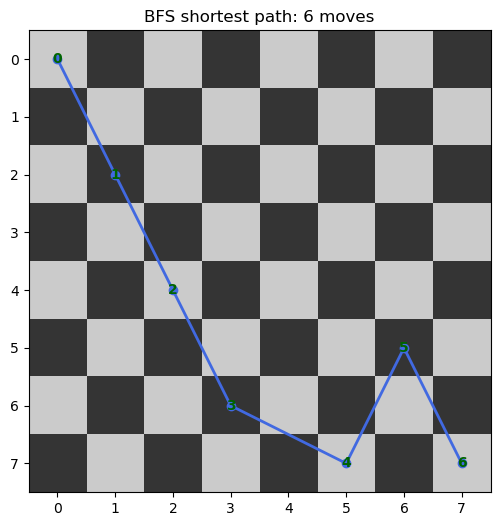

In [4]:
def display_numbered_path(path, title):
    """Display a numbered knight path on a chessboard."""
    board_colours = [
        [(row + col) % 2 for col in range(N)]
        for row in range(N)
    ]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(
        board_colours,
        cmap='binary',
        vmin=-0.35,
        vmax=1.35,
        origin='upper'
    )

    x_values = [col for row, col in path]
    y_values = [row for row, col in path]

    ax.plot(
        x_values,
        y_values,
        color='royalblue',
        marker='o',
        linewidth=2
    )

    for move_number, (row, col) in enumerate(path):
        ax.text(
            col,
            row,
            str(move_number),
            ha='center',
            va='center',
            color='darkgreen',
            fontweight='bold'
        )

    ax.set_xticks(range(N), labels=range(N))
    ax.set_yticks(range(N), labels=range(N))
    ax.set_xlim(-0.5, 7.5)
    ax.set_ylim(7.5, -0.5)
    ax.set_title(title)
    ax.grid(False)
    plt.show()


display_numbered_path(
    bfs_path,
    f'BFS shortest path: {len(bfs_path) - 1} moves'
)

## Exercise 1: A similar BFS problem

Use BFS to find a shortest knight path from

$$
(0,7) \quad \text{to} \quad (7,0).
$$

Your program should:

1. print one shortest path;
2. print the minimum number of moves;
3. display the numbered path on the board;
4. print the number of squares removed from the queue before the destination is processed;
5. explain why the answer is guaranteed to be shortest.

Use the existing `bfs_shortest_path` and `display_numbered_path` functions. Then change the start to `(3, 3)` and compare the two minimum distances.

Starting square: (0, 7)
Destination square: (7, 0)
Shortest path: [(0, 7), (1, 5), (3, 6), (2, 4), (3, 2), (5, 1), (7, 0)]
Minimum number of moves: 6
Squares removed from the queue: 64


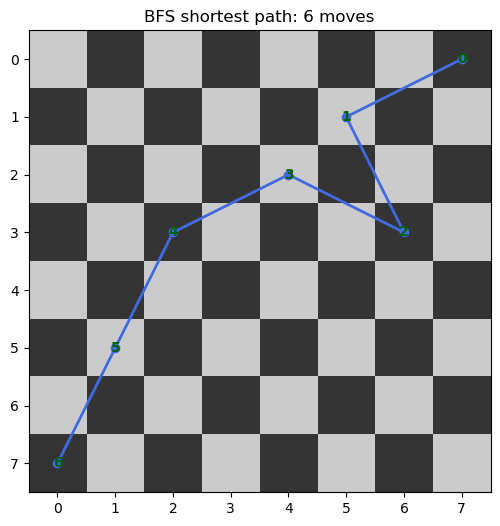


Starting square: (3, 3)
Shortest path: [(3, 3), (5, 4), (6, 2), (7, 0)]
Minimum number of moves: 3
Squares removed from the queue: 50


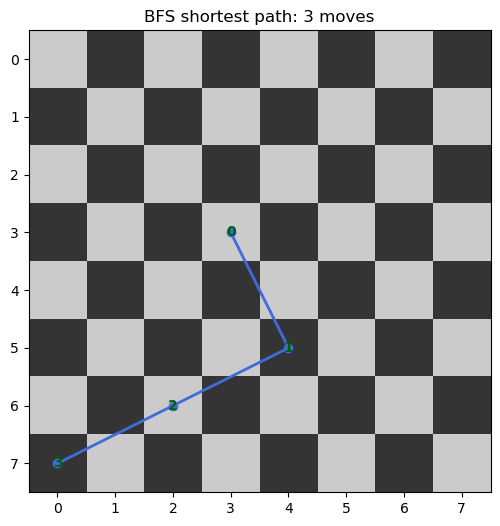


Comparison: (0,7)->(7,0) = 6 moves;  (3,3)->(7,0) = 3 moves


In [5]:
# Exercise 1 workspace

exercise_start = (0, 7)
exercise_destination = (7, 0)

# Call bfs_shortest_path.
bfs_path, bfs_distance, removal_order = bfs_shortest_path(
    exercise_start,
    exercise_destination
)

# Print the shortest path and minimum number of moves.
print('Starting square:', exercise_start)
print('Destination square:', exercise_destination)
print('Shortest path:', bfs_path)
print('Minimum number of moves:', len(bfs_path) - 1)
print('Squares removed from the queue:', len(removal_order))

# Display the path using display_numbered_path.
display_numbered_path(
    bfs_path,
    f'BFS shortest path: {len(bfs_path) - 1} moves'
)

# Change the start to (3, 3) and compare.
exercise_start = (3, 3)
bfs_path2, bfs_distance2, removal_order2 = bfs_shortest_path(
    exercise_start,
    exercise_destination
)
print('\nStarting square:', exercise_start)
print('Shortest path:', bfs_path2)
print('Minimum number of moves:', len(bfs_path2) - 1)
print('Squares removed from the queue:', len(removal_order2))
display_numbered_path(
    bfs_path2,
    f'BFS shortest path: {len(bfs_path2) - 1} moves'
)

print('\nComparison: (0,7)->(7,0) =', len(bfs_path) - 1,
      'moves;  (3,3)->(7,0) =', len(bfs_path2) - 1, 'moves')

# Part B: Closed Knight's Tour

## 4. What is a closed Knight's Tour?

A Knight's Tour is a sequence of legal knight moves that visits every square exactly once.

On an $8\times8$ board, a path

$$
v_1,v_2,\ldots,v_{64}
$$

is a **closed** Knight's Tour when:

1. the 64 squares are all distinct;
2. every consecutive pair $v_i,v_{i+1}$ is a legal knight move;
3. the last square $v_{64}$ is one knight move from the starting square $v_1$.

Thus, the path can be closed into a cycle. In graph terminology, it is a Hamiltonian cycle in the knight graph.

The next cell contains one verified tour for demonstration. The subsequent animation shows the knight following it. The DFS exercise later asks you to generate such a tour algorithmically.

In [6]:
# A previously computed closed tour used only for demonstration.
DEMO_CLOSED_TOUR = [
    (0, 0), (2, 1), (4, 0), (6, 1), (7, 3), (6, 5), (7, 7), (5, 6),
    (7, 5), (6, 7), (4, 6), (2, 7), (0, 6), (1, 4), (0, 2), (1, 0),
    (3, 1), (5, 0), (7, 1), (5, 2), (6, 0), (7, 2), (6, 4), (7, 6),
    (5, 7), (3, 6), (1, 7), (0, 5), (2, 6), (0, 7), (1, 5), (0, 3),
    (1, 1), (3, 0), (4, 2), (2, 3), (4, 4), (6, 3), (5, 1), (7, 0),
    (6, 2), (7, 4), (5, 5), (4, 7), (6, 6), (5, 4), (3, 5), (4, 3),
    (2, 2), (3, 4), (5, 3), (4, 1), (3, 3), (4, 5), (3, 7), (2, 5),
    (1, 3), (0, 1), (2, 0), (3, 2), (2, 4), (1, 6), (0, 4), (1, 2)
]


def verify_closed_tour(path):
    """Verify all conditions required for a closed Knight's Tour."""
    if len(path) != N * N:
        return False

    if len(set(path)) != N * N:
        return False

    for index in range(N * N - 1):
        if path[index + 1] not in NEIGHBOURS[path[index]]:
            return False

    if path[0] not in NEIGHBOURS[path[-1]]:
        return False

    return True


print('Number of squares:', len(DEMO_CLOSED_TOUR))
print('All squares are distinct:', len(set(DEMO_CLOSED_TOUR)) == 64)
print('Closed tour verified:', verify_closed_tour(DEMO_CLOSED_TOUR))
print('First square:', DEMO_CLOSED_TOUR[0])
print('Last square:', DEMO_CLOSED_TOUR[-1])
print('Last connects to first:',
      DEMO_CLOSED_TOUR[0] in NEIGHBOURS[DEMO_CLOSED_TOUR[-1]])

Number of squares: 64
All squares are distinct: True
Closed tour verified: True
First square: (0, 0)
Last square: (1, 2)
Last connects to first: True


## 5. Animation of the closed tour

Run the next cell and use the controls below the chessboard. The red marker is the current knight position, the blue line is the path already travelled, and the numbers give the visiting order.

In [7]:
def animate_closed_tour(path, interval=180):
    """Create an interactive JavaScript animation of a closed tour."""
    if not verify_closed_tour(path):
        raise ValueError('The supplied path is not a closed Knight\'s Tour.')

    board_colours = [
        [(row + col) % 2 for col in range(N)]
        for row in range(N)
    ]

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.imshow(
        board_colours,
        cmap='binary',
        vmin=-0.35,
        vmax=1.35,
        origin='upper'
    )
    ax.set_xticks(range(N), labels=range(N))
    ax.set_yticks(range(N), labels=range(N))
    ax.set_xlim(-0.5, 7.5)
    ax.set_ylim(7.5, -0.5)
    ax.grid(False)

    path_line, = ax.plot(
        [], [],
        color='royalblue',
        linewidth=2.2,
        marker='o',
        markersize=4
    )

    knight_marker, = ax.plot(
        [], [],
        marker='o',
        color='crimson',
        markersize=13
    )

    number_labels = []

    def update(frame):
        while number_labels:
            number_labels.pop().remove()

        partial_path = path[:frame + 1]
        x_values = [col for row, col in partial_path]
        y_values = [row for row, col in partial_path]

        path_line.set_data(x_values, y_values)
        knight_marker.set_data([x_values[-1]], [y_values[-1]])

        for move_number, (row, col) in enumerate(partial_path, start=1):
            number_labels.append(
                ax.text(
                    col,
                    row,
                    str(move_number),
                    ha='center',
                    va='center',
                    fontsize=7,
                    color='darkgreen',
                    fontweight='bold'
                )
            )

        if frame == len(path) - 1:
            ax.set_title(
                'Closed tour complete: square 64 connects to square 1'
            )
        else:
            ax.set_title(
                f'Closed Knight\'s Tour: move {frame + 1} of 64'
            )

        return [path_line, knight_marker, *number_labels]

    animation = FuncAnimation(
        fig,
        update,
        frames=len(path),
        interval=interval,
        repeat=False,
        blit=False
    )

    plt.close(fig)
    return HTML(animation.to_jshtml())


display(animate_closed_tour(DEMO_CLOSED_TOUR))

# Part C: DFS and backtracking

## 6. DFS idea

Depth-First Search extends one candidate path as deeply as possible. If the current partial tour cannot be completed, DFS returns to the most recent choice and tries another move.

For the Knight's Tour, the changing search state contains:

- the current square;
- the ordered partial path;
- the set of visited squares.

A recursive DFS uses Python's function-call stack. The essential pattern is:

```text
mark the chosen square
continue recursively
if the continuation fails, unmark the square
```

The unmarking operation restores the earlier state. This is **backtracking**.

### Practical move ordering

Plain DFS can be extremely slow. A useful ordering rule is:

> Try first the candidate square having the fewest currently unvisited onward moves.

This is Warnsdorff ordering. It does not replace DFS; it only determines which DFS branch is explored first.

### DFS pseudocode for a closed tour

```text
DFS(current, start, path, visited):
    if path contains 64 squares:
        return whether current is a knight-neighbour of start

    candidates = all unvisited knight-neighbours of current
    order candidates by increasing onward-move count

    for each next_square in candidates:
        add next_square to path
        add next_square to visited

        if DFS(next_square, start, path, visited) succeeds:
            return True

        remove next_square from path
        remove next_square from visited

    return False
```

The final closure test is indispensable. A path that visits all 64 squares is an open tour unless its last square also connects to its first square.

## Exercise 2: Find a closed Knight's Tour using DFS

Write a recursive DFS program that finds a closed Knight's Tour beginning at `(0, 0)`.

### Requirements

1. Maintain a `path` list and a `visited` set.
2. Use recursive DFS.
3. Backtrack by removing a failed move from both structures.
4. Order candidates using their number of unvisited onward moves.
5. Accept a 64-square path only when its last square connects to the start.
6. Count the number of recursive calls and backtracks.
7. Verify the answer using `verify_closed_tour`.
8. Animate your computed path using `animate_closed_tour`.

### Questions to answer

- Why is unmarking a square necessary during backtracking?
- Why does choosing a low-onward-degree square first usually reduce the search?
- How would the stopping condition change for an open tour?

In [9]:
# Exercise 2 workspace: complete the DFS function.

def find_closed_tour_dfs(start=(0, 0)):
    path = [start]
    visited = {start}
    statistics = {
        'recursive_calls': 0,
        'backtracks': 0
    }

    def onward_degree(square):
        return sum(
            next_square not in visited
            for next_square in NEIGHBOURS[square]
        )

    def dfs(current):
        statistics['recursive_calls'] += 1

        # TODO 1: If path has 64 squares, test closure.
        if len(path) == N * N:
            return path[0] in NEIGHBOURS[current]

        # TODO 2: Form the list of unvisited neighbours.
        candidates = [
            next_square for next_square in NEIGHBOURS[current]
            if next_square not in visited
        ]

        # TODO 3: Sort candidates by onward_degree.
        candidates.sort(key=onward_degree)

        # TODO 4: For each candidate:
        #         add it to path and visited;
        #         call dfs recursively;
        #         if it fails, undo both additions and count a backtrack.
        for next_square in candidates:
            path.append(next_square)
            visited.add(next_square)

            if dfs(next_square):
                return True

            path.pop()
            visited.remove(next_square)
            statistics['backtracks'] += 1

        return False

    found = dfs(start)

    if found:
        return path, statistics

    return None, statistics


# After completing the function, run:
computed_tour, statistics = find_closed_tour_dfs((0, 0))
print('Statistics:', statistics)
print('Verified:', verify_closed_tour(computed_tour))
display(animate_closed_tour(computed_tour))

Statistics: {'recursive_calls': 117, 'backtracks': 53}
Verified: True


## 7. BFS and DFS comparison

### BFS shortest-path problem

- **Goal:** reach a specified destination in the minimum number of moves.
- **Data structure:** queue.
- **Exploration:** level by level.
- **State:** current square is sufficient.
- **Result:** a shortest path.

### DFS closed-tour problem

- **Goal:** visit every square exactly once and close the path.
- **Data structure:** recursive call stack.
- **Exploration:** extend one path deeply.
- **State:** current square, current path, and visited set.
- **Failure handling:** backtracking.
- **Result:** a closed Knight's Tour if the search succeeds.